# Notebook 2. Seoul Bikes – Recuperación de pipelines e inferencia

Curso: Machine Learning

Integrantes: Juan Esteban Giraldo Giraldo / Federico Avalos Zuleta

**Propósito:** recuperar los pipelines serializados en el Notebook 1 y utilizarlos para predecir las bicicletas rentadas por hora sin reentrenar el modelo.

**Condición:** ejecutar este notebook en el mismo proyecto, con los archivos generados por el Notebook 1 disponibles en `artifacts/`.

## 1. Verificar el entorno y cargar librerías

In [1]:
# Carga solo las librerías necesarias para recuperar artefactos, predecir y evaluar (no se importa ningún estimador)
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
# Define las rutas del proyecto y de los artefactos generados por el Notebook 1
RAIZ_PROYECTO = Path.cwd()
if RAIZ_PROYECTO.name == "notebooks":
    RAIZ_PROYECTO = RAIZ_PROYECTO.parent

RUTA_DATOS = RAIZ_PROYECTO / "dataset" / "SeoulBikeData.csv"
RUTA_ARTIFACTOS = RAIZ_PROYECTO / "artifacts"
RUTA_PREP = RUTA_ARTIFACTOS / "seoul_pipeline_prep.joblib"
RUTA_MODELO = RUTA_ARTIFACTOS / "seoul_pipeline_modelo.joblib"
RUTA_METADATA = RUTA_ARTIFACTOS / "seoul_metadata.json"
RUTA_REFERENCIA = RUTA_ARTIFACTOS / "seoul_predicciones_referencia.csv"

## 2. Recuperar los artefactos

Se cargan los dos pipelines y la metadata guardados en el Notebook 1. No se llama a `fit` en ningún momento.

**Advertencia de seguridad:** carga únicamente artefactos `.joblib` de procedencia confiable.

In [3]:
# Verifica que existan los artefactos y los carga junto con la metadata, sin reentrenar
for ruta in (RUTA_PREP, RUTA_MODELO, RUTA_METADATA, RUTA_REFERENCIA):
    if not ruta.exists():
        raise FileNotFoundError(
            f"No se encontró {ruta.name}. Ejecuta primero el Notebook 1."
        )

pipeline_prep = joblib.load(RUTA_PREP)
pipeline_modelo = joblib.load(RUTA_MODELO)
with open(RUTA_METADATA, encoding="utf-8") as f:
    metadata = json.load(f)

print("Pipeline de preprocesamiento:", pipeline_prep)
print("Pipeline de modelamiento:", pipeline_modelo)
print("Mejores hiperparámetros:", metadata["mejores_hiperparametros"])
print("Entrenado el:", metadata["fecha_entrenamiento"])

Pipeline de preprocesamiento: Pipeline(steps=[('columnas',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Hour', 'Humidity(%)',
                                                   'Temperature(°C)',
                                                   'Rainfall(mm)',
                                                   'Snowfall (cm)']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Seasons', 'Holiday',
                                                   'Day of week'])]))])
Pipeline de modelamiento: TransformedTargetRegressor(regressor=Pipeline(steps=[('escalador',
                                                      StandardScaler()),
                                             

### Comparar el entorno con el de entrenamiento

Una versión distinta de scikit-learn puede impedir la carga o cambiar los resultados.

In [4]:
# Compara las versiones de librerías actuales con las registradas en el entrenamiento
versiones = pd.DataFrame({
    "entrenamiento": metadata["versiones"],
    "actual": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "joblib": joblib.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
})
versiones["coincide"] = versiones["entrenamiento"] == versiones["actual"]
display(versiones)

if not versiones["coincide"].all():
    print("Advertencia: hay versiones distintas a las del entrenamiento.")

,entrenamiento,actual,coincide
python,3.13.3,3.13.3,True
scikit-learn,1.9.1,1.9.1,True
joblib,1.6.0,1.6.0,True
pandas,3.1.1,3.1.1,True
numpy,2.5.5,2.5.5,True


## 3. Reconstruir el conjunto de prueba

Para verificar que la recuperación conserva el comportamiento, se repite la misma limpieza previa y la misma partición del Notebook 1, con idénticos parámetros y semilla aleatoria (tomados de la metadata).

In [5]:
# Repite la limpieza previa y la misma partición (parámetros tomados de la metadata) para reconstruir el conjunto de prueba
def limpiar_datos(df):
    """Filtra días en funcionamiento, crea 'Day of week' e imputa la humedad en 0 %."""
    df = df[df["Functioning Day"] == "Yes"].copy()

    df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
    df["Day of week"] = df["Date"].dt.day_name().astype(str)

    # Humedad 0 % (imposible) -> NaN e interpolación lineal por hora
    df["Humidity(%)"] = df["Humidity(%)"].replace(0, np.nan)
    df["Humidity(%)"] = df.groupby("Hour")["Humidity(%)"].transform(
        lambda x: x.interpolate(method="linear")
    )
    return df.reset_index(drop=True)


datos = limpiar_datos(pd.read_csv(RUTA_DATOS, encoding="latin-1"))
X = datos[metadata["variables_entrada"]]
y = datos[metadata["variable_salida"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=metadata["division_datos"]["test_size"],
    random_state=metadata["division_datos"]["random_state"],
)

assert len(X_test) == metadata["division_datos"]["n_prueba"], "El tamaño de prueba no coincide."
print("Datos de prueba:", X_test.shape)

Datos de prueba: (2117, 8)


## 4. Ejecutar inferencia

`pipeline_prep` codifica las categóricas con las categorías aprendidas. Luego `pipeline_modelo` escala las entradas, aplica la red MLP y devuelve la predicción en la escala original. No se ajustan nuevamente los parámetros.

In [6]:
# Transforma la prueba con el preprocesamiento recuperado y predice con el modelo recuperado
X_test_prep = pipeline_prep.transform(X_test)
y_pred = pipeline_modelo.predict(X_test_prep)

print("Primeras 10 predicciones:", np.round(y_pred[:10], 1))

Primeras 10 predicciones: [1402.4  867.9 1081.5  349.7 1760.2  602.2 1060.3  223.1 2007.9  947.5]


## 5. Evaluar las predicciones recuperadas

Las métricas recalculadas deben coincidir con las guardadas en la metadata.

In [7]:
# Recalcula las métricas de prueba y las compara con las guardadas durante el entrenamiento
metricas_recuperadas = {
    "test_RMSE": float(np.sqrt(mean_squared_error(y_test, y_pred))),
    "test_MAE": float(mean_absolute_error(y_test, y_pred)),
    "test_R2": float(r2_score(y_test, y_pred)),
}

comparacion = pd.DataFrame({
    "entrenamiento": {k: metadata["metricas"][k] for k in metricas_recuperadas},
    "recuperado": metricas_recuperadas,
})
comparacion["coincide"] = np.isclose(comparacion["entrenamiento"], comparacion["recuperado"])
display(comparacion)
print("RMSE línea base (media):", round(metadata["metricas"]["baseline_RMSE_media"], 3))

,entrenamiento,recuperado,coincide
test_RMSE,227.391755,227.391755,True
test_MAE,147.757278,147.757278,True
test_R2,0.869075,0.869075,True


RMSE línea base (media): 628.613


## 6. Verificar la consistencia del proceso

Comprobación independiente entre sesiones: se comparan las predicciones actuales con el vector de predicciones de referencia guardado en el Notebook 1, usando los mismos índices de prueba.

In [8]:
# Compara las predicciones con el vector de referencia del Notebook 1 y muestra el error por observación
referencia = pd.read_csv(RUTA_REFERENCIA, index_col="indice")

assert referencia.index.equals(X_test.index), "Los índices de prueba no coinciden con la referencia."
assert np.allclose(referencia["predicho"].to_numpy(), y_pred), (
    "Las predicciones recuperadas difieren de las de referencia."
)
print("Verificación exitosa: las predicciones coinciden con la referencia del Notebook 1.")

resultados = pd.DataFrame({
    "real": y_test.to_numpy(),
    "predicho": np.round(y_pred, 1),
}, index=X_test.index)
resultados["error_abs"] = (resultados["real"] - resultados["predicho"]).abs()
display(resultados.head(15))

print("Error absoluto medio:", round(resultados["error_abs"].mean(), 2), "bicicletas")

Verificación exitosa: las predicciones coinciden con la referencia del Notebook 1.


,real,predicho,error_abs
5945,1232,1402.4,170.4
5292,964,867.9,96.1
5903,942,1081.5,139.5
879,373,349.7,23.3
6861,1259,1760.2,501.2
5723,476,602.2,126.2
4885,1062,1060.3,1.7
1452,253,223.1,29.9
7170,2857,2007.9,849.1
8170,1039,947.5,91.5


Error absoluto medio: 147.76 bicicletas


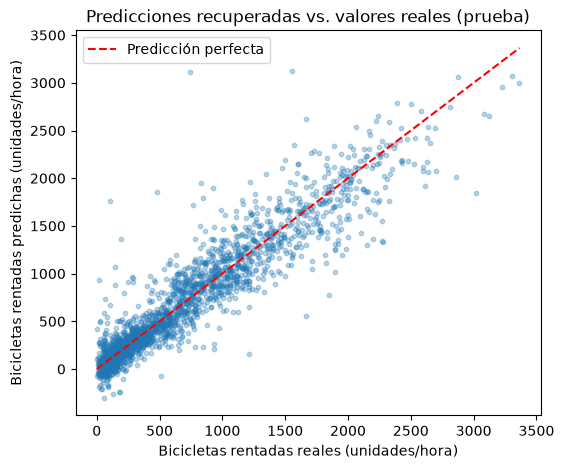

In [9]:
# Grafica las predicciones recuperadas contra los valores reales del conjunto de prueba
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(resultados["real"], resultados["predicho"], alpha=0.3, s=10)
limite = resultados[["real", "predicho"]].max().max()
ax.plot([0, limite], [0, limite], "r--", label="Predicción perfecta")
ax.set_xlabel("Bicicletas rentadas reales (unidades/hora)")
ax.set_ylabel("Bicicletas rentadas predichas (unidades/hora)")
ax.set_title("Predicciones recuperadas vs. valores reales (prueba)")
ax.legend()
plt.show()

**Análisis.** 
En este paso comprobamos que el modelo se guardó correctamente y no perdió nada de lo que aprendió. Al cargarlo desde el archivo, sin necesidad de volver a entrenarlo, reproduce la misma gráfica de predicciones y las mismas métricas que obtuvimos al principio (un R² de 0,87 y un error promedio de 148 bicicletas). Esto nos confirma que el modelo es totalmente reproducible y ya está listo para usarse en la práctica para hacer nuevos pronósticos.

## 7. Inferencia sobre nuevas observaciones

Se simula un lote de registros nuevos con las **variables crudas** que espera `pipeline_prep` (mismos nombres, orden y significado de columnas que en `metadata["variables_entrada"]`). En un caso real provendrían de un formulario, archivo o sistema operacional y deberían pasar antes por la misma limpieza previa (por ejemplo, calcular `Day of week` a partir de la fecha).

In [10]:
# Predice la demanda para un lote de horas nuevas con las mismas columnas crudas que espera pipeline_prep
X_nuevo = pd.DataFrame([
    {"Hour": 8,  "Humidity(%)": 60, "Temperature(°C)": 18.0, "Rainfall(mm)": 0.0, "Snowfall (cm)": 0.0,
     "Seasons": "Spring", "Holiday": "No Holiday", "Day of week": "Monday"},
    {"Hour": 18, "Humidity(%)": 55, "Temperature(°C)": 22.0, "Rainfall(mm)": 0.0, "Snowfall (cm)": 0.0,
     "Seasons": "Summer", "Holiday": "No Holiday", "Day of week": "Wednesday"},
    {"Hour": 18, "Humidity(%)": 90, "Temperature(°C)": 20.0, "Rainfall(mm)": 5.0, "Snowfall (cm)": 0.0,
     "Seasons": "Summer", "Holiday": "No Holiday", "Day of week": "Wednesday"},
    {"Hour": 14, "Humidity(%)": 40, "Temperature(°C)": -5.0, "Rainfall(mm)": 0.0, "Snowfall (cm)": 2.0,
     "Seasons": "Winter", "Holiday": "Holiday", "Day of week": "Sunday"},
    {"Hour": 3,  "Humidity(%)": 70, "Temperature(°C)": 10.0, "Rainfall(mm)": 0.0, "Snowfall (cm)": 0.0,
     "Seasons": "Autumn", "Holiday": "No Holiday", "Day of week": "Saturday"},
])[metadata["variables_entrada"]]

X_nuevo_prep = pipeline_prep.transform(X_nuevo)
predicciones_nuevas = pipeline_modelo.predict(X_nuevo_prep)

salida = X_nuevo.copy()
salida["bicicletas_predichas"] = np.clip(np.round(predicciones_nuevas), 0, None).astype(int)
display(salida)

,Hour,Humidity(%),Temperature(°C),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Day of week,bicicletas_predichas
0,8,60,18.0,0.0,0.0,Spring,No Holiday,Monday,1323
1,18,55,22.0,0.0,0.0,Summer,No Holiday,Wednesday,3443
2,18,90,20.0,5.0,0.0,Summer,No Holiday,Wednesday,455
3,14,40,-5.0,0.0,2.0,Winter,Holiday,Sunday,66
4,3,70,10.0,0.0,0.0,Autumn,No Holiday,Saturday,360


## 8. Actividad de análisis

1. ¿Por qué el Notebook 2 no necesita ejecutar `fit`?
2. ¿Qué sucedería si se modificara el orden o el nombre de las columnas de entrada?
3. ¿Qué ocurriría si se intentara cargar el pipeline con una versión incompatible de scikit-learn?
4. ¿Por qué deben conservarse conjuntamente el pipeline de preprocesamiento y el modelo?
5. ¿Qué cambios harías para desplegar esta solución como un servicio de predicción?

**Respuestas:**

1. Porque los parámetros ya fueron aprendidos en el Notebook 1 (medias y desviaciones de los escaladores, categorías del OneHotEncoder y pesos de la red) y quedaron guardados en los pipelines. Aquí solo se aplican con `transform` y `predict`. La prueba es que las métricas recalculadas (RMSE 227,39, MAE 147,76, R² 0,869) y las predicciones coinciden con las guardadas. Llamar a fit sería reentrenar y cambiaría los resultados.

2. Si cambia un nombre o falta una columna, el `ColumnTransformer` falla con un error, porque selecciona por nombre. Si solo cambia el orden, normalmente no pasa nada, salvo que los datos lleguen como arreglo sin nombres. Lo más peligroso es que cambie el significado con el mismo nombre (valores intercambiados, una categoría mal escrita), no hay error, pero la predicción es incorrecta. Por eso se reordena con `metadata["variables_entrada"]`y se validan los datos de entrada.

3. Puede fallar la carga, aparecer un InconsistentVersionWarning o, lo peor, cargar sin error y dar predicciones distintas. Por eso se compara el entorno con la metadata (aquí todas las versiones coinciden) y se reconstruye con `requirements-lock.txt`.

4. La red fue entrenada con datos escalados y codificados de una forma específica. Si se le entregan datos crudos, o transformados con otros parámetros, las entradas no significan lo mismo y la predicción pierde sentido.

5. Unir ambos pipelines (o cargarlos al iniciar) en una API (por ejemplo, FastAPI) con un endpoint `/predict` que reciba fecha, hora y clima; incluir la limpieza previa (calcular `Day of week`, validar rangos); validar el esquema de entrada; empaquetar en un contenedor Docker con el `requirements-lock.txt`; registrar las predicciones y monitorear la deriva de los datos y el error para decidir cuándo reentrenar.

### Preguntas de la guía del laboratorio

1. **Instalar globalmente vs. en `venv_ml`.** 

Una instalación global se comparte entre todos los proyectos del computador y puede generar conflictos de versiones. En `venv_ml` las librerías quedan aisladas para este proyecto, con versiones fijas que no afectan ni son afectadas por otros proyectos.

2. **Ventajas de `uv` frente a pip paquete por paquete.** 

Resuelve todas las dependencias a la vez y de forma consistente, es mucho más rápido (escrito en Rust, con caché), instala también la versión de Python y genera archivos de bloqueo reproducibles (`uv pip compile`, `uv pip sync`).

3. **`requirements.txt` vs. `requirements-lock.txt`.** 

El primero declara las dependencias directas con rangos permitidos (por ejemplo `scikit-learn>=1.6,<2.0`). El segundo lo genera `uv pip compile` y fija la versión exacta de cada paquete, incluidas las dependencias transitivas, para reconstruir exactamente el mismo entorno.

4. **¿Por qué no basta con guardar solo el modelo?** 

Porque el modelo espera datos ya escalados y codificados. Sin el preprocesamiento ajustado no hay forma de transformar los datos nuevos con las mismas medias, desviaciones y categorías, y las predicciones serían incorrectas.

5. **Qué aprenden `StandardScaler` y PCA.** 

El `StandardScaler` aprende la media y la desviación de cada variable; PCA aprende las direcciones de máxima varianza (componentes) y la varianza explicada. En el ejemplo del laboratorio se incluyen dentro del pipeline de modelamiento para que se ajusten solo con entrenamiento y viajen con el modelo. En nuestro caso no se usa PCA (hay pocas variables), pero se sigue la misma idea: el `StandardScaler` de las entradas está dentro de `pipeline_modelo`, igual que en el cuaderno principal, para que en la validación cruzada se ajuste solo con las particiones de entrenamiento; el escalado de la salida también está ahí, con `TransformedTargetRegressor`.

6. **Fuga de información.** 

Ocurre cuando información del conjunto de prueba (o del futuro) se filtra al entrenamiento, por ejemplo al escalar con todos los datos. Se evita dividiendo primero los datos, ajustando los pipelines solo con `X_train` y aplicando únicamente `transform`/`predict` en prueba e inferencia. La búsqueda de hiperparámetros también usa solo entrenamiento (validación cruzada).

7. **Riesgos de seguridad de los `.joblib`.** 

Al cargar un archivo pickle/joblib se puede ejecutar código arbitrario incluido en él. Un archivo de origen desconocido podría instalar malware o robar información. Solo deben cargarse artefactos de procedencia confiable y, idealmente, verificados con un hash.

8. **Versiones incompatibles de scikit-learn o NumPy.** 

La deserialización no está garantizada entre versiones: puede fallar la carga, aparecer advertencias o, en el peor caso, cargar sin error y entregar predicciones distintas. Por eso se guardan las versiones en la metadata y se reconstruye el entorno con el archivo de bloqueo.

## 9. Cierre

Se reconstruyó el flujo de inferencia a partir de artefactos guardados, sin reentrenar. Se recuperaron los pipelines y la metadata, se verificó que el entorno coincide con el del entrenamiento,tambien se reconstruyó el conjunto de prueba y se predijo solo con transform y predict. 

Las métricas y las predicciones coinciden con las del Notebook 1: RMSE de 227,39, MAE de 147,76 y R² de 0,869, frente a un RMSE de 628,61 de la línea base. Es decir, el error baja cerca de un 64 % y el modelo explica alrededor del 87 % de la variabilidad.

Las predicciones nuevas son coherentes: la mayor demanda es en la tarde de verano (3443 bicicletas), la lluvia la reduce mucho (455) y un día feriado de invierno con nieve casi no tiene uso (66). Como limitación, el modelo tiende a subestimar los picos de demanda (un caso real de 2857 se predijo como 2008) y no debe usarse en condiciones muy distintas a las del entrenamiento.

En conclusión, entrenar y predecir son procesos distintos: el primero aprende parámetros y el segundo los reutiliza. Para que esto funcione hay que conservar juntos el preprocesamiento y el modelo, registrar las versiones del entorno y validar que los datos nuevos tengan la misma estructura que los de entrenamiento.